# Математическая статистика. Лабораторная работа № 2
## Вариант 18. Угляниц Наталия
### Проверка статистических гипотез

**Цель работы:** проверить гипотезы о распределениях, математических ожиданиях и дисперсиях, а также сравнить средние двух частей каждой выборки.

Уровень значимости $\alpha=0.05$. Наблюдения считаются независимыми и одинаково распределёнными внутри каждой выборки. Для проверок параметров используются двусторонние альтернативы.

Обозначения:
$$\bar x=\frac1n\sum_{j=1}^n x_j,\qquad
v_n=\frac1n\sum_{j=1}^n(x_j-\bar x)^2,\qquad
S^2=\frac1{n-1}\sum_{j=1}^n(x_j-\bar x)^2.$$
$v_n$ — выборочная дисперсия с делителем $n$, $S^2$ — исправленная дисперсия, $S=\sqrt{S^2}$. Квантили индексируются вероятностью слева: $P(T\le q_p)=p$. Квадратные скобки $[x]$ означают целую часть $\lfloor x\rfloor$.

## Содержание
1. [Исходные данные](#data)
2. [Выборка A: распределение, среднее, дисперсия и сравнение частей](#sample-a)
3. [Выборка B: распределение, среднее, дисперсия и сравнение частей](#sample-b)
4. [Общие выводы](#results)
5. [Дополнительные расчёты](#extra)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from IPython.display import display, Markdown

plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11,
                     "axes.grid": True, "grid.alpha": .25, "figure.autolayout": True})
alpha = .05
zcrit = stats.norm.ppf(1-alpha/2)
results = []
def table(df, digits=6):
    display(df.style.format(precision=digits).format(
        {col: lambda value: f"{value:.6g}" for col in df.columns if col == "p" or col.startswith("p ")}
    ).hide(axis="index"))
def note(s): display(Markdown(s))
def decision(p): return "H₀ отвергается" if p < alpha else "Нет оснований отвергать H₀"

<a id="data"></a>
## Исходные данные
Рассматриваются выборки A18 и B18. A состоит из дискретных наблюдений; B рассматривается как реализация непрерывной величины, записанная целыми числами.

Для оценивания моделей B используется интервальный ряд с границами $20,25,\ldots,85$. При проверке среднего, дисперсии и при вычислении расстояния Колмогорова используются исходные значения B. Исходный порядок наблюдений сохраняется для последующего разделения выборок на две части.

In [2]:
import numpy as np

A = np.array([
    5, 3, 3, 3, 5, 4, 5, 3, 3, 4, 2, 1, 5, 2, 4, 0, 2, 2, 3, 2,
    1, 3, 3, 1, 2, 4, 6, 6, 4, 1, 2, 4, 3, 1, 5, 2, 4, 6, 3, 8,
    4, 5, 1, 1, 2, 0, 2, 3, 3, 2, 4, 2, 1, 2, 3, 1, 2, 4, 3, 0,
    6, 3, 1, 4, 3, 7, 1, 1, 0, 2, 3, 1, 1,
], dtype=int)

B = np.array([
    52, 40, 47, 54, 40, 54, 41, 74, 45, 45, 51, 76, 58, 37, 40,
    42, 53, 54, 65, 46, 65, 61, 55, 38, 66, 42, 56, 54, 40, 60,
    43, 49, 77, 64, 53, 64, 58, 54, 56, 53, 43, 35, 56, 34, 59,
    58, 66, 49, 49, 57, 48, 42, 46, 52, 59, 50, 62, 50, 55, 55,
    46, 53, 51, 50, 60, 30, 48, 56, 29, 74, 52, 60, 44, 62, 23,
    54, 40, 33, 20, 55, 42, 61, 54, 41, 45, 75, 59, 41, 51, 45,
    54, 52, 62, 69, 65, 49, 48, 63, 52, 46, 44, 55, 60, 54, 39,
    82, 67, 68, 34, 56, 51, 56, 48, 53, 47, 59, 51, 59, 66, 48,
    61, 42, 54, 33, 39, 47, 46, 47, 73, 63, 34, 44, 51, 46, 40,
    43, 30, 60, 61, 53, 47, 42, 56, 70, 48, 45, 65, 48, 48, 51,
    40, 57, 56, 33, 44, 43, 45, 35, 35, 56, 59, 66, 56, 52, 44,
    53, 49, 55, 25, 53, 48, 73, 38, 58, 72, 57, 46, 54, 55, 59,
    38, 53, 48, 68, 36, 53, 41, 55, 51, 50, 45, 50, 29, 60, 39,
    50, 59, 33, 56, 49, 31, 70, 56, 56,
], dtype=int)

In [3]:
assert len(A) == 73 and A.sum() == 208
assert len(B) == 204 and B.sum() == 10437
nA, nB = len(A), len(B)
edges = np.arange(20, 90, 5)
fB, _ = np.histogram(B, edges)
mid = (edges[:-1]+edges[1:])/2
Bg = np.repeat(mid, fB)
mean_group, dB = Bg.mean(), Bg.var()
table(pd.DataFrame([{"Выборка": name, "n": len(x), "Сумма": x.sum(),
    "Среднее": x.mean(), "vₙ": x.var(), "S²": x.var(ddof=1),
    "σₙ": x.std(), "m₄": np.mean((x-x.mean())**4)}
    for name, x in [("A18", A), ("B18, исходная", B), ("B18, середины интервалов", Bg)]]))

Выборка,n,Сумма,Среднее,vₙ,S²,σₙ,m₄
A18,73,208.000000,2.849315,2.977294,3.018645,1.725484,27.091154
"B18, исходная",204,10437.000000,51.161765,117.527754,118.106708,10.841022,43627.436847
"B18, середины интервалов",204,10550.000000,51.715686,119.482891,120.071477,10.930823,44340.393489


<a id="sample-a"></a>
## Часть A
### 1.1. Проверка гипотез по критерию Пирсона

**Что проверяем.** Сопоставляем наблюдаемые частоты A с частотами, ожидаемыми при распределениях Пуассона и отрицательном биномиальном. Критерий показывает, достаточно ли велико расхождение, чтобы отвергнуть модель.

**Гипотезы и критерий.**

Для каждой модели проверяются гипотезы:

$$H_{0P}:X\sim\operatorname{Pois}(\lambda),\qquad
H_{1P}:\text{распределение не является пуассоновским};$$
$$H_{0NB}:X\sim\operatorname{NB}(r,p),\qquad
H_{1NB}:\text{распределение не является отрицательным биномиальным}.$$

Вероятности отдельных значений:
$$P_P(X=j)=e^{-\lambda}\frac{\lambda^j}{j!},\quad\lambda>0,$$
$$P_{NB}(X=j)=\frac{\Gamma(j+r)}{\Gamma(r)j!}p^r(1-p)^j,
\quad r>0,\quad0<p<1,\quad j=0,1,\ldots.$$

Начальные оценки методом моментов:
$$\hat\lambda=\bar x,\qquad \hat p=\frac{\bar x}{v_n},\qquad
\hat r=\frac{\bar x^2}{v_n-\bar x}.$$

Объединяем крайние значения в категории $\{0,1\},\{2\},\{3\},\{4\},\{5,6,\ldots\}$.
Последняя категория включает весь правый хвост распределения. Для критерия уточняем параметры методом максимального правдоподобия по этим пяти категориям:
$$\ell(\theta)=\sum_{i=1}^{5}n_i\ln p_i(\theta)\longrightarrow\max_\theta.$$
Для NB используем параметризацию $p=r/(r+\mu)$, где $\mu>0$ — среднее. Проверяем допустимость оценок, сходимость из нескольких начальных точек и положительность ожидаемых частот.

Наблюдаемые и ожидаемые частоты обозначим $n_i$ и $n_i'=np_i$. Статистика:
$$\chi^2_{\rm набл}=\sum_{i=1}^{k}\frac{(n_i-n_i')^2}{n_i'}.$$
После объединения $k=5$, все $n_i'\ge5$. Число степеней свободы $\nu=k-1-q$, где $q$ — число оценённых параметров: 1 для Пуассона и 2 для NB.

При $\alpha=0.05$ критическая область:
$$\chi^2_{\rm набл}>\chi^2_{0.95,\nu}.$$
Калибровка критерия асимптотическая. Ниже приведены исходные таблицы частот с полным хвостом, объединённые таблицы и результаты проверки.

Модель,Параметры
Пуассон,λ = 2.849315
NB,r = 63.436950; p = 0.957015


Параметр,Метод моментов,ММП по пяти группам
λ Пуассона,2.849315,2.826758
r NB,63.436950,29.512543
p NB,0.957015,0.912242


**Проверка оценивания:** несколько начальных точек дали одинаковый максимум; параметры допустимы, локальная кривизна отрицательного log L положительна. Пуассоновский предел NB проверен сравнением значений правдоподобия.

**Пуассон: исходная таблица частот.**

xᵢ,nᵢ,pᵢ,nᵢ′ = npᵢ
0,4,0.059204,4.321928
1,14,0.167357,12.217043
2,15,0.236539,17.267312
3,17,0.222879,16.270170
4,11,0.157506,11.497958
5,6,0.089046,6.500389
6,4,0.041952,3.062504
7,1,0.016941,1.236708
8,1,0.005986,0.436984
≥9,0,0.002589,0.189003


**Отрицательное биномиальное: исходная таблица частот.**

... (4 outputs left out)

**NB: расчётная таблица.**

Группа,nᵢ,pᵢ,nᵢ′ = npᵢ,(nᵢ−nᵢ′)²/nᵢ′
0–1,18,0.238693,17.424553,0.019004
2,15,0.230556,16.830570,0.199101
3,17,0.212532,15.514815,0.142172
4,11,0.151600,11.066827,0.000404
≥5,12,0.166620,12.163235,0.002191


**Подстановка:** X² = 0.019004 + 0.199101 + 0.142172 + 0.000404 + 0.002191 = 0.362872; ν = 5 − 1 − 2 = 2; χ² крит = 5.991465. Критическая область: (5.991465; +∞).

Модель,χ²,ν,χ² крит,p (прибл.),Решение
Пуассон,0.509960,3,7.814728,0.916698,Нет оснований отвергать H₀
NB,0.362872,2,5.991465,0.834072,Нет оснований отвергать H₀


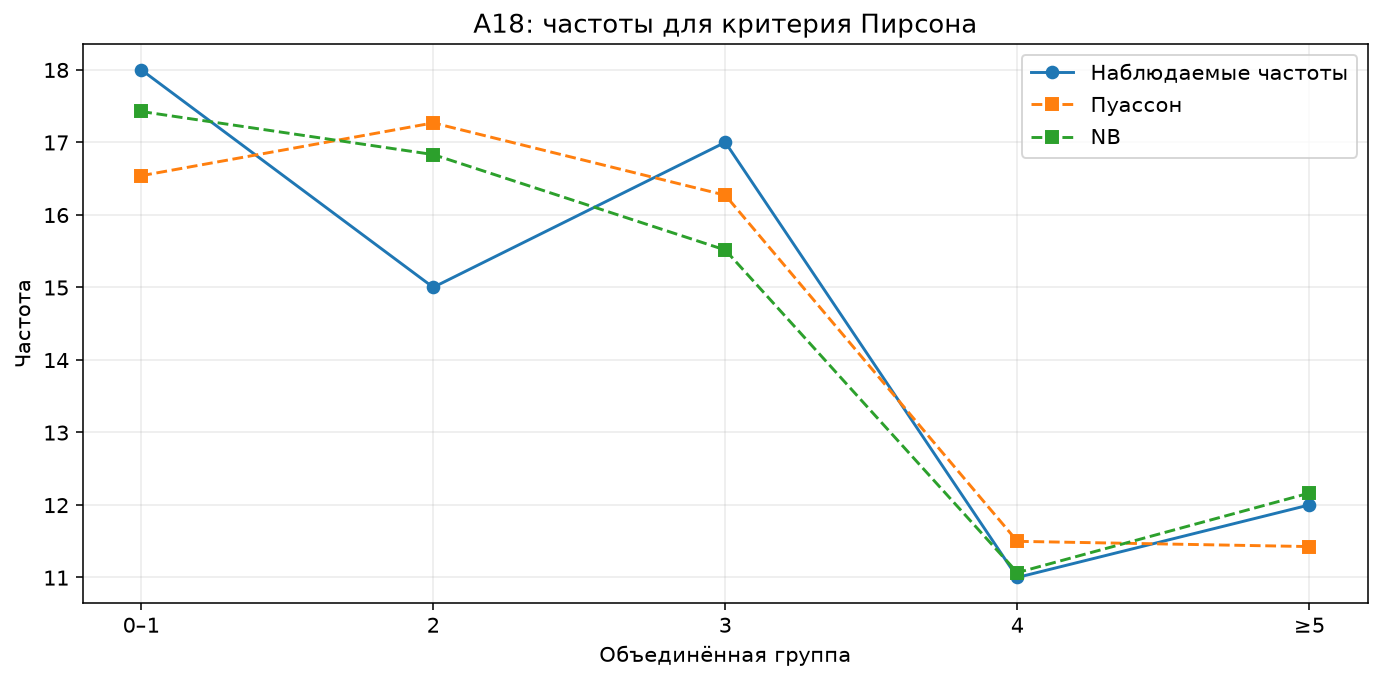

In [4]:
lam, varA = A.mean(), A.var()
p_nb, r_nb = lam/varA, lam**2/(varA-lam)
pois, nbinom = stats.poisson(lam), stats.nbinom(r_nb, p_nb)
table(pd.DataFrame({"Модель": ["Пуассон", "NB"], "Параметры":
    [f"λ = {lam:.6f}", f"r = {r_nb:.6f}; p = {p_nb:.6f}"]}))
observed = np.array([(A <= 1).sum(), (A == 2).sum(), (A == 3).sum(),
                     (A == 4).sum(), (A >= 5).sum()])
labels = ["0–1", "2", "3", "4", "≥5"]
def group_prob(rv):
    return np.r_[rv.cdf(1), rv.pmf([2,3,4]), rv.sf(4)]
def group_nll(rv):
    probabilities = group_prob(rv)
    if np.any(probabilities <= 0):
        return np.inf
    return -float(np.dot(observed, np.log(probabilities)))
pois_mm, nb_mm = pois, nbinom
fit_p = optimize.minimize_scalar(lambda log_lam: group_nll(stats.poisson(np.exp(log_lam))),
    bounds=(-5, 5), method='bounded', options={'xatol':1e-11})
lambda_group = float(np.exp(fit_p.x))
def nb_group_nll(theta):
    mean, r = np.exp(theta)
    return group_nll(stats.nbinom(r, r/(r+mean)))
fits_nb = [optimize.minimize(nb_group_nll, np.log([lam, start]), method='Nelder-Mead',
    options={'maxiter':4000, 'xatol':1e-8, 'fatol':1e-10}) for start in [5, 30, 100]]
assert fit_p.success and all(f.success for f in fits_nb)
fit_nb_group = min(fits_nb, key=lambda fit:fit.fun)
mu_group_A, r_group = np.exp(fit_nb_group.x)
p_group = r_group/(r_group+mu_group_A)
pois = stats.poisson(lambda_group)
nbinom = stats.nbinom(r_group, p_group)
assert abs(fit_p.x) < 4.9 and 0 < p_group < 1 and r_group > 0
assert np.ptp([fit.fun for fit in fits_nb]) < 1e-7
assert group_nll(pois) <= group_nll(pois_mm)+1e-8
assert group_nll(nbinom) <= group_nll(nb_mm)+1e-8
assert group_nll(nbinom) < group_nll(pois)
# Численная проверка внутреннего минимума отрицательного log L.
eps = 1e-3
center = fit_nb_group.x
curvature = np.empty((2,2))
for j in range(2):
    ej = np.eye(2)[j]*eps
    curvature[j,j] = (nb_group_nll(center+ej)-2*nb_group_nll(center)+nb_group_nll(center-ej))/eps**2
e0,e1 = np.eye(2)*eps
curvature[0,1] = curvature[1,0] = (nb_group_nll(center+e0+e1)-nb_group_nll(center+e0-e1)
    -nb_group_nll(center-e0+e1)+nb_group_nll(center-e0-e1))/(4*eps**2)
assert np.all(np.linalg.eigvalsh(curvature) > 0)
table(pd.DataFrame({"Параметр": ["λ Пуассона", "r NB", "p NB"],
    "Метод моментов": [lam, r_nb, p_nb],
    "ММП по пяти группам": [lambda_group, r_group, p_group]}))
note("**Проверка оценивания:** несколько начальных точек дали одинаковый максимум; "
     "параметры допустимы, локальная кривизна отрицательного log L положительна. "
     "Пуассоновский предел NB проверен сравнением значений правдоподобия.")
# Полные исходные частоты, включая ненаблюдавшийся хвост.
values = np.arange(A.max()+1)
raw_observed = np.r_[[np.count_nonzero(A == value) for value in values], 0]
raw_labels = [str(value) for value in values]+[f"≥{A.max()+1}"]
for name, rv in [("Пуассон", pois), ("Отрицательное биномиальное", nbinom)]:
    raw_probs = np.r_[rv.pmf(values), rv.sf(A.max())]
    assert np.isclose(raw_probs.sum(), 1) and raw_observed.sum() == nA
    note(f"**{name}: исходная таблица частот.**")
    table(pd.DataFrame({"xᵢ": raw_labels, "nᵢ": raw_observed,
                        "pᵢ": raw_probs, "nᵢ′ = npᵢ": nA*raw_probs}))
pearson_rows = []
for name, rv, q in [("Пуассон", pois, 1), ("NB", nbinom, 2)]:
    probs = np.r_[rv.cdf(1), rv.pmf([2,3,4]), rv.sf(4)]
    expected = nA*probs
    terms = (observed-expected)**2/expected
    chi, df = terms.sum(), len(observed)-1-q
    critical, p = stats.chi2.ppf(.95, df), stats.chi2.sf(chi, df)
    assert np.isclose(probs.sum(), 1) and observed.sum() == nA and min(expected) >= 5
    note(f"**{name}: расчётная таблица.**")
    table(pd.DataFrame({"Группа": labels, "nᵢ": observed, "pᵢ": probs,
                        "nᵢ′ = npᵢ": expected, "(nᵢ−nᵢ′)²/nᵢ′": terms}))
    assert np.isclose(chi, stats.chisquare(observed, expected, ddof=q).statistic)
    assert np.isclose(p, stats.chisquare(observed, expected, ddof=q).pvalue)
    note(f"**Подстановка:** X² = {' + '.join(f'{term:.6f}' for term in terms)} = {chi:.6f}; "
         f"ν = 5 − 1 − {q} = {df}; χ² крит = {critical:.6f}. "
         f"Критическая область: ({critical:.6f}; +∞).")
    pearson_rows.append({"Модель": name, "χ²": chi, "ν": df, "χ² крит": critical,
                         "p (прибл.)": p, "Решение": decision(p)})
    results.append({"Пункт": "1.1, "+name, "Статистика": chi, "p": p, "Решение": decision(p)})
pearson = pd.DataFrame(pearson_rows)
table(pearson)
fig, ax = plt.subplots()
ax.plot(labels, observed, 'o-', label="Наблюдаемые частоты")
for name, rv in [("Пуассон", pois), ("NB", nbinom)]:
    ax.plot(labels, nA*np.r_[rv.cdf(1), rv.pmf([2,3,4]), rv.sf(4)], 's--', label=name)
ax.set(xlabel="Объединённая группа", ylabel="Частота", title="A18: частоты для критерия Пирсона")
ax.legend(); plt.show()

### 1.2. Сравнение распределений
Сравниваем модели по одной группировке. Меньшее значение $\chi^2$ означает меньшее взвешенное расхождение частот. При выборе модели дополнительно учитывается число её параметров.

In [5]:
best_a = pearson.loc[pearson["χ²"].idxmin(), "Модель"]
note("**Вывод.** На уровне значимости 0,05 обе гипотезы не отвергаются: "
     f"для Пуассона χ²={pearson_rows[0]['χ²']:.4f} < {pearson_rows[0]['χ² крит']:.4f}; "
     f"для отрицательного биномиального закона χ²={pearson_rows[1]['χ²']:.4f} < {pearson_rows[1]['χ² крит']:.4f}. "
     "По величине расхождения частот лучше соответствует отрицательное биномиальное распределение. "
     "Его преимущество по χ² невелико, и оно использует два параметра вместо одного; исключать распределение Пуассона оснований нет.")

**Вывод.** На уровне значимости 0,05 обе гипотезы не отвергаются: для Пуассона χ²=0.5100 < 7.8147; для отрицательного биномиального закона χ²=0.3629 < 5.9915. По величине расхождения частот лучше соответствует отрицательное биномиальное распределение. Его преимущество по χ² невелико, и оно использует два параметра вместо одного; исключать распределение Пуассона оснований нет.

### 1.3. Проверка гипотезы о неизвестном среднем

**Что проверяем.** Выясняем, можно ли объяснить отличие среднего выборки от 2,5 случайным разбросом. Для этого делим разность на стандартную ошибку среднего.

**Гипотезы и критерий.**
$$H_0:a=a_0,\qquad H_1:a\ne a_0,$$
$$a_0=\lfloor\bar x_A\rfloor+0.5=2.5.$$
При конечной дисперсии выборочное среднее асимптотически нормально. Используем статистику
$$Z_a=\frac{\bar x-a_0}{S/\sqrt n}\approx N(0,1).$$
Для двусторонней проверки $z_{\rm кр}=z_{0.975}=1.959964$.
Отвергаем $H_0$ при $|Z_a|>z_{\rm кр}$; $p=2\Phi(-|Z_a|)$.

In [6]:
def mean_test(x, a0, label):
    n, mean, s2 = len(x), x.mean(), x.var(ddof=1)
    se = np.sqrt(s2/n)
    u = (mean-a0)/se
    p = 2*stats.norm.sf(abs(u))
    table(pd.DataFrame([{"Выборка": label, "a₀": a0, "Среднее": mean,
        "S²": s2, "SE": se, "Z": u, "z крит": zcrit, "p": p, "Решение": decision(p)}]))

    note(rf"$$Z_a=\frac{{{mean:.6f}-{a0:.6f}}}{{\sqrt{{{s2:.6f}/{n}}}}}={u:.6f}.$$")
    ci = mean + np.array([-1,1])*zcrit*se
    assert (ci[0] <= a0 <= ci[1]) == (p >= alpha)
    if p < alpha:
        conclusion = f"Гипотеза a={a0:g} отвергается: отличие среднего {mean:.4f} от {a0:g} статистически значимо."
    else:
        conclusion = f"Гипотеза a={a0:g} не отвергается: отличие среднего {mean:.4f} от {a0:g} статистически незначимо."
    note(f"**Вывод для {label}.** {conclusion} |Z|={abs(u):.4f}, критическая граница {zcrit:.4f}; p={p:.4g}, α={alpha:g}.")
    return u, p
a0_A = np.floor(A.mean())+.5
ua, pa = mean_test(A, a0_A, "A18")
results.append({"Пункт": "1.3, среднее A", "Статистика": ua, "p": pa, "Решение": decision(pa)})

Выборка,a₀,Среднее,S²,SE,Z,z крит,p,Решение
A18,2.500000,2.849315,3.018645,0.203350,1.717800,1.959964,0.085833,Нет оснований отвергать H₀


$$Z_a=\frac{2.849315-2.500000}{\sqrt{3.018645/73}}=1.717800.$$

**Вывод для A18.** Гипотеза a=2.5 не отвергается: отличие среднего 2.8493 от 2.5 статистически незначимо. |Z|=1.7178, критическая граница 1.9600; p=0.08583, α=0.05.

### 1.4. Проверка гипотезы о неизвестной дисперсии

**Что проверяем.** Сравниваем наблюдаемый разброс A с нулевой дисперсией 1,5. Стандартная ошибка оценки дисперсии учитывает четвёртый момент, поскольку большие отклонения особенно сильно влияют на разброс.

**Гипотезы и критерий.**
$$H_0:\sigma^2=\sigma_0^2,\qquad H_1:\sigma^2\ne\sigma_0^2,$$
$$\sigma_0^2=\lfloor\sqrt{v_n}\rfloor+0.5=1.5.$$
В формуле задания внутри целой части стоит стандартное отклонение. Расчёт для другого прочтения формулы приведён в приложении.

При существовании четвёртого момента
$$\sqrt n(v_n-\sigma^2)\Rightarrow N(0,\mu_4-\sigma^4).$$
Поэтому используем асимптотическую статистику
$$Z_v=\frac{v_n-\sigma_0^2}{\sqrt{(m_4-v_n^2)/n}},\qquad
m_4=\frac1n\sum_{j=1}^n(x_j-\bar x)^4.$$
При $H_0$ приближённо $Z_v\sim N(0,1)$. Критическая область $|Z_v|>1.959964$.

Используем нормальное приближение для оценки дисперсии. Точный χ²-критерий требует нормальности исходных наблюдений и для дискретной A не применяется.

In [7]:
def variance_test(x, v0, label):
    n, v = len(x), x.var()
    m4 = np.mean((x-x.mean())**4)
    se = np.sqrt((m4-v*v)/n)
    assert se > 0 and v0 > 0
    u = (v-v0)/se
    p = 2*stats.norm.sf(abs(u))
    table(pd.DataFrame([{"Выборка": label, "σ₀²": v0, "vₙ": v, "m₄": m4,
        "SE": se, "Z": u, "z крит": zcrit, "p": p, "Решение": decision(p)}]))

    note(rf"$$Z_v=\frac{{{v:.6f}-{v0:.6f}}}{{\sqrt{{({m4:.6f}-{v:.6f}^2)/{n}}}}}={u:.6f}.$$")
    ci = v + np.array([-1,1])*zcrit*se
    assert (ci[0] <= v0 <= ci[1]) == (p >= alpha)
    if p < alpha:
        direction = "выше" if v > v0 else "ниже"
        conclusion = f"Гипотеза σ²={v0:g} отвергается. Наблюдаемая дисперсия {v:.4f} {direction} заданного значения; отклонение статистически значимо."
    else:
        conclusion = f"Гипотеза σ²={v0:g} не отвергается. Отличие наблюдаемой дисперсии {v:.4f} от {v0:g} статистически незначимо."
    note(f"**Вывод для {label}.** {conclusion} |Z|={abs(u):.4f}, критическая граница {zcrit:.4f}; p={p:.4g}, α={alpha:g}.")
    return u, p
v0_A = np.floor(A.std())+.5
uv, pv = variance_test(A, v0_A, "A18")
results.append({"Пункт": "1.4, дисперсия A", "Статистика": uv, "p": pv, "Решение": decision(pv)})

Выборка,σ₀²,vₙ,m₄,SE,Z,z крит,p,Решение
A18,1.500000,2.977294,27.091154,0.499683,2.956462,1.959964,0.00311191,H₀ отвергается


$$Z_v=\frac{2.977294-1.500000}{\sqrt{(27.091154-2.977294^2)/73}}=2.956462.$$

**Вывод для A18.** Гипотеза σ²=1.5 отвергается. Наблюдаемая дисперсия 2.9773 выше заданного значения; отклонение статистически значимо. |Z|=2.9565, критическая граница 1.9600; p=0.003112, α=0.05.

### 1.5. Проверка гипотезы о равенстве средних

**Что проверяем.** Сравниваем средние начала и конца выборки. Части выделяем до сортировки: иначе разделение само создало бы различие средних.

**Гипотезы и критерий.**
Разделим A в исходном порядке: первая часть содержит первые 36 наблюдений, вторая — оставшиеся 37.
$$H_0:a_1=a_2,\qquad H_1:a_1\ne a_2.$$
Дисперсии неизвестны, но предполагаются равными. Объединённая оценка:
$$S_p^2=\frac{(n_1-1)S_1^2+(n_2-1)S_2^2}{n_1+n_2-2}.$$
Статистика Стьюдента:
$$T=\frac{\bar x_1-\bar x_2}{\sqrt{S_p^2(1/n_1+1/n_2)}}.$$
Число степеней свободы $\nu=36+37-2=71$. Критическая область $|T|>t_{0.975,71}$.
Для независимых нормальных выборок с общей дисперсией критерий точный; для дискретной A используется приближение. Неотклонение гипотезы не доказывает равенство средних.

In [8]:
def split_test(x, label):
    cut = len(x)//2
    x1, x2 = x[:cut], x[cut:]
    n1, n2 = len(x1), len(x2)
    m1, m2 = x1.mean(), x2.mean()
    s1, s2 = x1.var(ddof=1), x2.var(ddof=1)
    df = n1+n2-2
    sp2 = ((n1-1)*s1+(n2-1)*s2)/df
    t = (m1-m2)/np.sqrt(sp2*(1/n1+1/n2))
    p, crit = 2*stats.t.sf(abs(t), df), stats.t.ppf(.975, df)
    check = stats.ttest_ind(x1, x2, equal_var=True)
    assert np.isclose(t, check.statistic) and np.isclose(p, check.pvalue)
    table(pd.DataFrame({"Часть": [f"1…{cut}", f"{cut+1}…{len(x)}"],
                        "n": [n1,n2], "Среднее": [m1,m2], "S²": [s1,s2]}))
    table(pd.DataFrame([{"Выборка": label, "Sₚ²": sp2, "T": t, "ν": df,
                        "t крит": crit, "p": p, "Решение": decision(p)}]))

    note(rf"$$S_p^2=\frac{{({n1}-1)\cdot {s1:.6f}+({n2}-1)\cdot {s2:.6f}}}{{{n1}+{n2}-2}}={sp2:.6f}.$$")
    note(rf"$$T=\frac{{{m1:.6f}-{m2:.6f}}}{{\sqrt{{{sp2:.6f}(1/{n1}+1/{n2})}}}}={t:.6f}.$$")
    note(f"Критическая область: T < −{crit:.6f} или T > {crit:.6f}; ν={df}.")
    finding = "обнаружено" if p < alpha else "не обнаружено"
    note(f"**Вывод для {label}.** Средние частей равны {m1:.4f} и {m2:.4f}; разность составляет {m1-m2:.4f}. "
         f"На уровне α={alpha:g} статистически значимое различие средних {finding} "
         f"(|T|={abs(t):.4f}, tкр={crit:.4f}, p={p:.4g}). "
         "Проверка относится к средним и не устанавливает совпадение распределений целиком.")
    return t,p
ta, pta = split_test(A, "A18")
results.append({"Пункт": "1.5, половины A", "Статистика": ta, "p": pta, "Решение": decision(pta)})

Часть,n,Среднее,S²
1…36,36,3.027778,2.313492
37…73,37,2.675676,3.725225


Выборка,Sₚ²,T,ν,t крит,p,Решение
A18,3.029300,0.864148,71,1.993943,0.390417,Нет оснований отвергать H₀


$$S_p^2=\frac{(36-1)\cdot 2.313492+(37-1)\cdot 3.725225}{36+37-2}=3.029300.$$

$$T=\frac{3.027778-2.675676}{\sqrt{3.029300(1/36+1/37)}}=0.864148.$$

Критическая область: T < −1.993943 или T > 1.993943; ν=71.

**Вывод для A18.** Средние частей равны 3.0278 и 2.6757; разность составляет 0.3521. На уровне α=0.05 статистически значимое различие средних не обнаружено (|T|=0.8641, tкр=1.9939, p=0.3904). Проверка относится к средним и не устанавливает совпадение распределений целиком.

<a id="sample-b"></a>
## Часть B
### 2.1. Проверка гипотез по критерию Колмогорова

**Что проверяем.** Сравниваем накопленные доли наблюдений B с теоретическими функциями распределения. В отличие от сравнения отдельных частот, здесь оценивается наибольшее расхождение накопленных вероятностей.

**Гипотезы и критерий.**
Рассматриваются нормальное распределение и симметричное треугольное распределение Симпсона. Для каждой модели:
$$H_0:F=F_\theta,\qquad H_1:F\text{ не принадлежит выбранному семейству}.$$

Нормальная модель имеет параметры $\hat\mu=\bar x_{\rm гр}$, $\hat\sigma^2=v_{\rm гр}$, рассчитанные по серединам интервалов с учётом частот.

Для распределения Симпсона $c=(a+b)/2$, $d=(b-a)/2>0$ и
$$F_S(x)=\begin{cases}
0,&x<a,\\
(x-a)^2/(2d^2),&a\le x\le c,\\
1-(b-x)^2/(2d^2),&c<x\le b,\\
1,&x>b.
\end{cases}$$
Параметры оцениваются максимизацией интервального правдоподобия
$$\ell(c,d)=\sum_i n_i\ln\bigl(F_S(b_i)-F_S(a_i)\bigr).$$
Включаются также хвостовые категории с нулевыми наблюдёнными частотами; сумма всех вероятностей равна 1.

In [9]:
mu = mean_group; sigma2 = dB; sigma = np.sqrt(dB)
normal = stats.norm(mu, sigma)
c_sim_mm = mean_group
d_sim_mm = np.sqrt(6*dB)
a_sim_mm, b_sim_mm = c_sim_mm-d_sim_mm, c_sim_mm+d_sim_mm
simpson_mm = stats.triang(.5, loc=a_sim_mm, scale=2*d_sim_mm)
category_edges = np.r_[-np.inf, edges, np.inf]
category_counts = np.r_[0, fB, 0]
filled = category_counts > 0
def simpson_nll(theta):
    center, log_halfwidth = theta
    halfwidth = np.exp(log_halfwidth)
    rv = stats.triang(.5, loc=center-halfwidth, scale=2*halfwidth)
    probabilities = np.diff(rv.cdf(category_edges))
    if np.any(probabilities[filled] <= 0):
        return 1e100
    return -float(np.dot(category_counts[filled], np.log(probabilities[filled])))
starts = [(mean_group, edges[-1]-edges[0]),
          ((edges[0]+edges[-1])/2, edges[-1]-edges[0]),
          (mean_group, 1.25*max(mean_group-edges[0], edges[-1]-mean_group))]
fits_sim = [optimize.minimize(simpson_nll, [center, np.log(width)],
            method='Nelder-Mead', options={'xatol': 1e-9, 'fatol': 1e-9, 'maxiter': 5000})
            for center, width in starts]
assert all(fit.success for fit in fits_sim)
fit_sim = min(fits_sim, key=lambda fit: fit.fun)
c_sim_ml, d_sim_ml = float(fit_sim.x[0]), float(np.exp(fit_sim.x[1]))
a_sim_ml, b_sim_ml = c_sim_ml-d_sim_ml, c_sim_ml+d_sim_ml
simpson = stats.triang(.5, loc=a_sim_ml, scale=2*d_sim_ml)
simpson_probabilities = np.diff(simpson.cdf(category_edges))
assert np.all(simpson_probabilities[filled] > 0)
assert np.isclose(simpson_probabilities.sum(), 1)

In [10]:
table(pd.DataFrame({"Модель": ["Нормальная", "Симпсон"], "Параметры":
    [f"μ={mu:.6f}; σ²={sigma2:.6f}", f"a={a_sim_ml:.6f}; b={b_sim_ml:.6f}; c={c_sim_ml:.6f}; d={d_sim_ml:.6f}"]}))

Модель,Параметры
Нормальная,μ=51.715686; σ²=119.482891
Симпсон,a=22.163150; b=81.617607; c=51.890378; d=29.727229


Эмпирическая функция распределения:
$$F_n(x)=\frac1n\sum_{j=1}^n\mathbf1\{X_j\le x\}.$$
Для упорядоченных исходных наблюдений вычисляем отклонения с обеих сторон каждого скачка:
$$D_n^+=\max_i\left(\frac in-F_0(x_{(i)})\right),\qquad
D_n^-=\max_i\left(F_0(x_{(i)})-\frac{i-1}{n}\right),$$
$$D_n=\max(D_n^+,D_n^-),\qquad \lambda_{\rm набл}=\sqrt nD_n.$$
При $\alpha=0.05$ табличное критическое значение $\lambda_{\rm кр}=1.358099$. Критическая область $\lambda_{\rm набл}>\lambda_{\rm кр}$.

**Ограничение проверки.** Параметры оценены по той же выборке, а наблюдения округлены до целых. Поэтому сравнение с границей 1,358099 является формальным: ниже отдельно указаны табличное решение и сравнение моделей по расстоянию. Точный уровень ошибки 5% для этих подогнанных моделей не утверждается.

Модель,D+,D−,D,√nD,λ крит,p формальное,Формальное решение
Нормальная,0.077940,0.022256,0.077940,1.113213,1.358099,0.167641,Нет оснований отвергать H₀
Симпсон,0.101704,0.052559,0.101704,1.452617,1.358099,0.0293915,H₀ отвергается


**Критическая граница для D:** 0.095086.

**Нормальная: таблица для критерия Колмогорова.**

xᵢ,nᵢ,Fₙ(xᵢ−),Fₙ(xᵢ),F₀(xᵢ),dᵢ+,dᵢ−
20,1,0.000000,0.004902,0.001857,0.003045,0.001857
23,1,0.004902,0.009804,0.004307,0.005497,-0.000595
25,1,0.009804,0.014706,0.007261,0.007445,-0.002543
29,2,0.014706,0.024510,0.018849,0.005661,0.004143
30,2,0.024510,0.034314,0.023481,0.010833,-0.001029
31,1,0.034314,0.039216,0.029035,0.010180,-0.005278
33,4,0.039216,0.058824,0.043430,0.015393,0.004215
34,3,0.058824,0.073529,0.052540,0.020989,-0.006284
35,3,0.073529,0.088235,0.063104,0.025131,-0.010425
36,1,0.088235,0.093137,0.075254,0.017883,-0.012981


**Симпсон: таблица для критерия Колмогорова.**

xᵢ,nᵢ,Fₙ(xᵢ−),Fₙ(xᵢ),F₀(xᵢ),dᵢ+,dᵢ−
20,1,0.000000,0.004902,0.000000,0.004902,0.000000
23,1,0.004902,0.009804,0.000396,0.009408,-0.004506
25,1,0.009804,0.014706,0.004553,0.010153,-0.005251
29,2,0.014706,0.024510,0.026447,-0.001937,0.011741
30,2,0.024510,0.034314,0.034749,-0.000435,0.010239
31,1,0.034314,0.039216,0.044183,-0.004967,0.009869
33,4,0.039216,0.058824,0.066446,-0.007622,0.027230
34,3,0.058824,0.073529,0.079274,-0.005745,0.020451
35,3,0.073529,0.088235,0.093235,-0.005000,0.019705
36,1,0.088235,0.093137,0.108327,-0.015189,0.020091


**Нормальная:** D=max(0.077940; 0.022256)=0.077940; λ=√204 × 0.077940=1.113213. Критическая область: λ>1.358099.

**Симпсон:** D=max(0.101704; 0.052559)=0.101704; λ=√204 × 0.101704=1.452617. Критическая область: λ>1.358099.

**Точки наибольшего расхождения для обеих сторон скачков:**

Модель,Сторона,x,Fₙ(x−),Fₙ(x),F₀(x),Отклонение
Нормальная,После скачка,56,0.666667,0.730392,0.652452,0.077940
Нормальная,До скачка,53,0.524510,0.573529,0.546766,0.022256
Симпсон,После скачка,56,0.666667,0.730392,0.628689,0.101704
Симпсон,До скачка,40,0.127451,0.161765,0.180010,0.052559


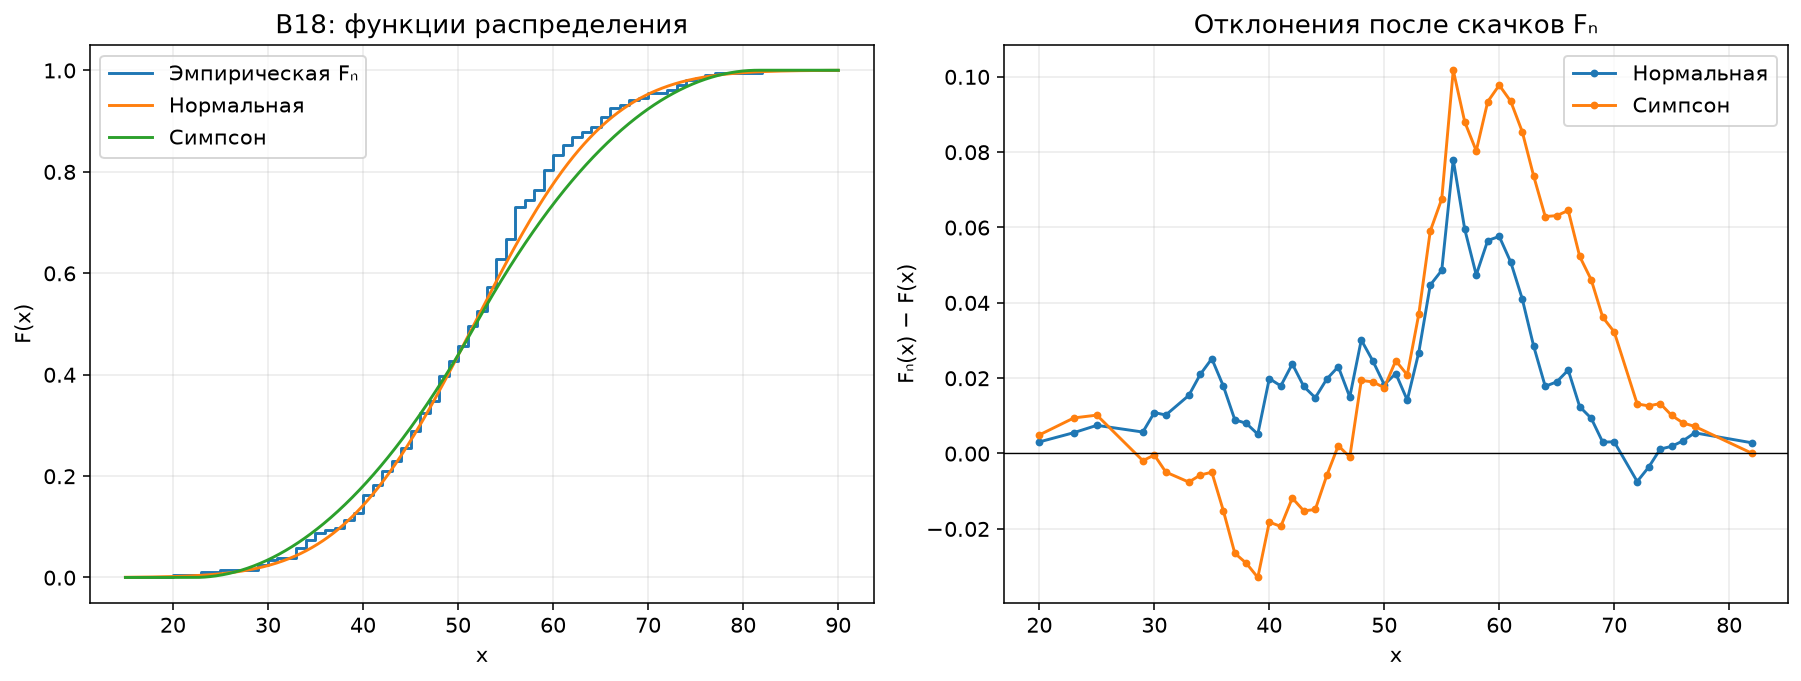

In [11]:
xb = np.sort(B)
i = np.arange(1, nB+1)
kcrit = stats.kstwobign.ppf(.95)
ks_rows = []
ks_details = pd.DataFrame({"i": i, "x(i)": xb, "(i−1)/n": (i-1)/nB, "i/n": i/nB})
for name, rv in [("Нормальная", normal), ("Симпсон", simpson)]:
    F = rv.cdf(xb)
    plus, minus = i/nB-F, F-(i-1)/nB
    dp, dm = plus.max(), minus.max()
    D = max(dp, dm)
    statistic = np.sqrt(nB)*D
    p_formal = stats.kstwobign.sf(statistic)
    assert np.isclose(D, stats.kstest(B, rv.cdf).statistic)
    ks_details["F: "+name] = F
    ks_details["D+: "+name] = plus
    ks_details["D−: "+name] = minus
    ks_rows.append({"Модель": name, "D+": dp, "D−": dm, "D": D,
        "√nD": statistic, "λ крит": kcrit, "p формальное": p_formal,
        "Формальное решение": decision(p_formal)})
    results.append({"Пункт": "2.1, "+name+" (формально)", "Статистика": statistic,
                    "p": p_formal, "Решение": decision(p_formal)})
ks = pd.DataFrame(ks_rows)
table(ks)
note(f"**Критическая граница для D:** {kcrit/np.sqrt(nB):.6f}.")
# Выводим уникальные значения; обе стороны каждого скачка вычислены выше.
unique_b, counts_b = np.unique(B, return_counts=True)
cumulative = counts_b.cumsum()/nB
for name, rv in [("Нормальная", normal), ("Симпсон", simpson)]:
    F0 = rv.cdf(unique_b)
    note(f"**{name}: таблица для критерия Колмогорова.**")
    table(pd.DataFrame({"xᵢ": unique_b, "nᵢ": counts_b,
        "Fₙ(xᵢ−)": cumulative-counts_b/nB, "Fₙ(xᵢ)": cumulative, "F₀(xᵢ)": F0,
        "dᵢ+": cumulative-F0, "dᵢ−": F0-(cumulative-counts_b/nB)}))
max_rows = []
for name, rv in [("Нормальная", normal), ("Симпсон", simpson)]:
    plus = cumulative-rv.cdf(unique_b)
    minus = rv.cdf(unique_b)-(cumulative-counts_b/nB)
    jplus, jminus = int(np.argmax(plus)), int(np.argmax(minus))
    for side, j, value in [("После скачка", jplus, plus[jplus]), ("До скачка", jminus, minus[jminus])]:
        max_rows.append({"Модель": name, "Сторона": side, "x": unique_b[j],
            "Fₙ(x−)": cumulative[j]-counts_b[j]/nB, "Fₙ(x)": cumulative[j],
            "F₀(x)": rv.cdf(unique_b[j]), "Отклонение": value})
    D = max(plus.max(), minus.max())
    assert np.isclose(D, stats.kstest(B, rv.cdf).statistic)
    note(f"**{name}:** D=max({plus.max():.6f}; {minus.max():.6f})={D:.6f}; "
         f"λ=√{nB} × {D:.6f}={np.sqrt(nB)*D:.6f}. Критическая область: λ>{kcrit:.6f}.")
note("**Точки наибольшего расхождения для обеих сторон скачков:**")
table(pd.DataFrame(max_rows))
grid = np.linspace(15, 90, 900)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].step(np.r_[15, unique_b,90], np.r_[0,cumulative,1], where='post', label="Эмпирическая Fₙ")
for name, rv in [("Нормальная",normal), ("Симпсон",simpson)]:
    axes[0].plot(grid, rv.cdf(grid), label=name)
    axes[1].plot(unique_b, cumulative-rv.cdf(unique_b), '.-', label=name)
axes[0].set(title="B18: функции распределения", xlabel="x", ylabel="F(x)")
axes[1].axhline(0, color="black", lw=.7)
axes[1].set(title="Отклонения после скачков Fₙ", xlabel="x", ylabel="Fₙ(x) − F(x)")
for ax in axes: ax.legend()
plt.show()

### 2.2. Сравнение распределений
Меньшая статистика $D_n$ означает меньшее максимальное отклонение теоретической функции распределения от эмпирической. Сравнение выполняется по всем исходным значениям с учётом обеих сторон скачков.

In [12]:
best_b = ks.loc[ks["D"].idxmin(), "Модель"]
note("**Вывод.** Нормальное распределение ближе к наблюдаемой B: "
     f"D={ks_rows[0]['D']:.4f} против {ks_rows[1]['D']:.4f} у Симпсона. "
     f"При табличной границе {kcrit:.4f} нормальная гипотеза формально не отвергается "
     f"(λ={ks_rows[0]['√nD']:.4f}), а гипотеза Симпсона формально отвергается "
     f"(λ={ks_rows[1]['√nD']:.4f}). "
     "Для описания этой выборки из двух рассмотренных моделей предпочтительна нормальная. "
     "Из-за оценивания параметров по этим же данным табличные решения не являются откалиброванной проверкой семейств на уровне 5%.")

**Вывод.** Нормальное распределение ближе к наблюдаемой B: D=0.0779 против 0.1017 у Симпсона. При табличной границе 1.3581 нормальная гипотеза формально не отвергается (λ=1.1132), а гипотеза Симпсона формально отвергается (λ=1.4526). Для описания этой выборки из двух рассмотренных моделей предпочтительна нормальная. Из-за оценивания параметров по этим же данным табличные решения не являются откалиброванной проверкой семейств на уровне 5%.

### 2.3. Проверка гипотезы о неизвестном среднем

**Что проверяем.** Определяем, значимо ли отличие наблюдаемого среднего B от 50,5. Поскольку проверяется любое отличие, критическая область располагается в обоих хвостах.

**Гипотезы и критерий.**
$$H_0:a=a_0,\qquad H_1:a\ne a_0,$$
$$a_0=\lfloor\bar x_B\rfloor-0.5=50.5.$$
Используем исходные наблюдения и статистику
$$Z_a=\frac{\bar x_B-a_0}{S_B/\sqrt{n_B}}\approx N(0,1).$$
При $\alpha=0.05$ критическая область $|Z_a|>1.959964$.

In [13]:
a0_B = np.floor(B.mean())-.5
ub, pb = mean_test(B, a0_B, "B18")
results.append({"Пункт": "2.3, среднее B", "Статистика": ub, "p": pb, "Решение": decision(pb)})

Выборка,a₀,Среднее,S²,SE,Z,z крит,p,Решение
B18,50.500000,51.161765,118.106708,0.760891,0.869724,1.959964,0.384451,Нет оснований отвергать H₀


$$Z_a=\frac{51.161765-50.500000}{\sqrt{118.106708/204}}=0.869724.$$

**Вывод для B18.** Гипотеза a=50.5 не отвергается: отличие среднего 51.1618 от 50.5 статистически незначимо. |Z|=0.8697, критическая граница 1.9600; p=0.3845, α=0.05.

### 2.4. Проверка гипотезы о неизвестной дисперсии

**Что проверяем.** Выясняем, совместим ли наблюдаемый разброс B с дисперсией 9,5. Используем тот же асимптотический критерий, что и для A, с моментами исходной выборки B.

**Гипотезы и критерий.**
$$H_0:\sigma^2=\sigma_0^2,\qquad H_1:\sigma^2\ne\sigma_0^2,$$
$$\sigma_0^2=\lfloor\sqrt{v_{n,B}}\rfloor-0.5=9.5.$$
Используем асимптотическую нормальность оценки дисперсии:
$$Z_v=\frac{v_{n,B}-\sigma_0^2}{\sqrt{(m_{4,B}-v_{n,B}^2)/n_B}}.$$
Моменты рассчитываются по исходной B. Критическая область $|Z_v|>1.959964$.

In [14]:
v0_B = np.floor(B.std())-.5
uvb, pvb = variance_test(B, v0_B, "B18")
results.append({"Пункт": "2.4, дисперсия B", "Статистика": uvb, "p": pvb, "Решение": decision(pvb)})

Выборка,σ₀²,vₙ,m₄,SE,Z,z крит,p,Решение
B18,9.500000,117.527754,43627.436847,12.089264,8.935842,1.959964,4.0409e-19,H₀ отвергается


$$Z_v=\frac{117.527754-9.500000}{\sqrt{(43627.436847-117.527754^2)/204}}=8.935842.$$

**Вывод для B18.** Гипотеза σ²=9.5 отвергается. Наблюдаемая дисперсия 117.5278 выше заданного значения; отклонение статистически значимо. |Z|=8.9358, критическая граница 1.9600; p=4.041e-19, α=0.05.

### 2.5. Проверка гипотезы о равенстве средних

**Что проверяем.** Сравниваем средние первых и последних 102 наблюдений. Общую неизвестную дисперсию оцениваем по обеим частям вместе.

**Гипотезы и критерий.**
Разделим B на первые 102 и последние 102 наблюдения.
$$H_0:a_1=a_2,\qquad H_1:a_1\ne a_2.$$
При неизвестных равных дисперсиях:
$$S_p^2=\frac{101S_1^2+101S_2^2}{202},\qquad
T=\frac{\bar x_1-\bar x_2}{\sqrt{S_p^2(1/102+1/102)}}.$$
Число степеней свободы $\nu=202$. Критическая область $|T|>t_{0.975,202}$.
Критерий точный при независимости, нормальности и общей дисперсии; в общем случае используется как приближённый.

In [15]:
tb, ptb = split_test(B, "B18")
results.append({"Пункт": "2.5, половины B", "Статистика": tb, "p": ptb, "Решение": decision(ptb)})

Часть,n,Среднее,S²
1…102,102,51.568627,117.475442
103…204,102,50.754902,119.572996


Выборка,Sₚ²,T,ν,t крит,p,Решение
B18,118.524219,0.533777,202,1.971777,0.594083,Нет оснований отвергать H₀


$$S_p^2=\frac{(102-1)\cdot 117.475442+(102-1)\cdot 119.572996}{102+102-2}=118.524219.$$

$$T=\frac{51.568627-50.754902}{\sqrt{118.524219(1/102+1/102)}}=0.533777.$$

Критическая область: T < −1.971777 или T > 1.971777; ν=202.

**Вывод для B18.** Средние частей равны 51.5686 и 50.7549; разность составляет 0.8137. На уровне α=0.05 статистически значимое различие средних не обнаружено (|T|=0.5338, tкр=1.9718, p=0.5941). Проверка относится к средним и не устанавливает совпадение распределений целиком.

<a id="results"></a>
## Общие выводы
Результаты относятся к уровню значимости 0,05 и основному прочтению нулевой дисперсии в условии. Для Колмогорова в таблице показано формальное табличное решение.

In [16]:
table(pd.DataFrame(results))
note("**Выборка A.** Обе модели распределения проходят проверку Пирсона; отрицательное биномиальное распределение имеет меньшее расхождение частот. "
     "Гипотеза о среднем a=2,5 не отвергается. Гипотеза о дисперсии σ²=1,5 отвергается: наблюдаемый разброс значительно выше. "
     "Значимого различия средних первых 36 и последних 37 наблюдений не обнаружено.")
note("**Выборка B.** Нормальная модель ближе к эмпирическому распределению, чем модель Симпсона. "
     "Гипотеза о среднем a=50,5 не отвергается. Гипотеза о дисперсии σ²=9,5 отвергается: наблюдаемый разброс значительно выше. "
     "Значимого различия средних двух частей по 102 наблюдения не обнаружено.")
assert all(0 <= row["p"] <= 1 for row in results)
assert np.isclose(fB.sum(), nB) and observed.sum() == nA


Пункт,Статистика,p,Решение
"1.1, Пуассон",0.509960,0.916698,Нет оснований отвергать H₀
"1.1, NB",0.362872,0.834072,Нет оснований отвергать H₀
"1.3, среднее A",1.717800,0.085833,Нет оснований отвергать H₀
"1.4, дисперсия A",2.956462,0.00311191,H₀ отвергается
"1.5, половины A",0.864148,0.390417,Нет оснований отвергать H₀
"2.1, Нормальная (формально)",1.113213,0.167641,Нет оснований отвергать H₀
"2.1, Симпсон (формально)",1.452617,0.0293915,H₀ отвергается
"2.3, среднее B",0.869724,0.384451,Нет оснований отвергать H₀
"2.4, дисперсия B",8.935842,4.0409e-19,H₀ отвергается
"2.5, половины B",0.533777,0.594083,Нет оснований отвергать H₀


**Выборка A.** Обе модели распределения проходят проверку Пирсона; отрицательное биномиальное распределение имеет меньшее расхождение частот. Гипотеза о среднем a=2,5 не отвергается. Гипотеза о дисперсии σ²=1,5 отвергается: наблюдаемый разброс значительно выше. Значимого различия средних первых 36 и последних 37 наблюдений не обнаружено.

**Выборка B.** Нормальная модель ближе к эмпирическому распределению, чем модель Симпсона. Гипотеза о среднем a=50,5 не отвергается. Гипотеза о дисперсии σ²=9,5 отвергается: наблюдаемый разброс значительно выше. Значимого различия средних двух частей по 102 наблюдения не обнаружено.

<a id="extra"></a>
## Приложение. Дополнительные расчёты
**Неоднозначность нулевой дисперсии.** Если в формуле задания подразумевалась целая часть дисперсии, а не стандартного отклонения, то
$$\sigma_{0,A}^2=\lfloor v_{n,A}\rfloor+0.5=2.5,\qquad
\sigma_{0,B}^2=\lfloor v_{n,B}\rfloor-0.5=116.5.$$
Ниже проверены эти альтернативные значения. Они не заменяют основной расчёт.

Дополнительно оценивается влияние замены исходных значений B серединами интервалов при тех же основных нулевых гипотезах. Такая замена даёт приближение к исходным данным.

Нулевые значения среднего и дисперсии заданы правилом, зависящим от выборки. Полученные $p$-значения относятся к подставленным гипотезам и не обеспечивают контроль ошибки всей процедуры выбора гипотезы. Уровень 0,05 относится к каждой проверке отдельно.

In [17]:
variance_test(A, np.floor(A.var())+.5, "A: альтернативное прочтение")
variance_test(B, np.floor(B.var())-.5, "B: альтернативное прочтение")
note("**Контроль влияния группировки B** при тех же основных нулевых значениях:")
mean_test(Bg, a0_B, "B: середины интервалов")
variance_test(Bg, v0_B, "B: середины интервалов")

Выборка,σ₀²,vₙ,m₄,SE,Z,z крит,p,Решение
A: альтернативное прочтение,2.500000,2.977294,27.091154,0.499683,0.955194,1.959964,0.33948,Нет оснований отвергать H₀


$$Z_v=\frac{2.977294-2.500000}{\sqrt{(27.091154-2.977294^2)/73}}=0.955194.$$

**Вывод для A: альтернативное прочтение.** Гипотеза σ²=2.5 не отвергается. Отличие наблюдаемой дисперсии 2.9773 от 2.5 статистически незначимо. |Z|=0.9552, критическая граница 1.9600; p=0.3395, α=0.05.

Выборка,σ₀²,vₙ,m₄,SE,Z,z крит,p,Решение
B: альтернативное прочтение,116.500000,117.527754,43627.436847,12.089264,0.085014,1.959964,0.93225,Нет оснований отвергать H₀


$$Z_v=\frac{117.527754-116.500000}{\sqrt{(43627.436847-117.527754^2)/204}}=0.085014.$$

**Вывод для B: альтернативное прочтение.** Гипотеза σ²=116.5 не отвергается. Отличие наблюдаемой дисперсии 117.5278 от 116.5 статистически незначимо. |Z|=0.0850, критическая граница 1.9600; p=0.9323, α=0.05.

... (3 outputs left out)

**Вывод для B: середины интервалов.** Гипотеза a=50.5 не отвергается: отличие среднего 51.7157 от 50.5 статистически незначимо. |Z|=1.5846, критическая граница 1.9600; p=0.1131, α=0.05.

Выборка,σ₀²,vₙ,m₄,SE,Z,z крит,p,Решение
B: середины интервалов,9.500000,119.482891,44340.393489,12.139756,9.059728,1.959964,1.30776e-19,H₀ отвергается


$$Z_v=\frac{119.482891-9.500000}{\sqrt{(44340.393489-119.482891^2)/204}}=9.059728.$$

**Вывод для B: середины интервалов.** Гипотеза σ²=9.5 отвергается. Наблюдаемая дисперсия 119.4829 выше заданного значения; отклонение статистически значимо. |Z|=9.0597, критическая граница 1.9600; p=1.308e-19, α=0.05.